<a href="https://colab.research.google.com/github/VidhyaSriKS/Traffic-volume-analysis/blob/main/traffic_volume_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import files

uploaded = files.upload()

Saving archive.zip to archive.zip


In [15]:
import zipfile
import pandas as pd
import numpy as np

with zipfile.ZipFile("archive.zip") as z:
    df = pd.read_csv(z.open("Train.csv"))

df["date_time"] = pd.to_datetime(df["date_time"])
df = df.sort_values("date_time")
df = df.groupby("date_time")["traffic_volume"].mean()
df = df.resample("h").mean()
df = df.interpolate().ffill().bfill()

df = df.iloc[:20000]

print(df.head())
print("Total hourly records:", len(df))

date_time
2012-10-02 09:00:00    5545.0
2012-10-02 10:00:00    4516.0
2012-10-02 11:00:00    4767.0
2012-10-02 12:00:00    5026.0
2012-10-02 13:00:00    4918.0
Freq: h, Name: traffic_volume, dtype: float64
Total hourly records: 20000


In [16]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
data = scaler.fit_transform(df.values.reshape(-1, 1))

X, y = [], []

for i in range(24, len(data)):
    X.append(data[i-24:i])
    y.append(data[i])

X = np.array(X)
y = np.array(y)

split = int(len(X) * 0.8)

X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (15980, 24, 1)
Testing data: (3996, 24, 1)


In [17]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

model = Sequential([
    LSTM(32, input_shape=(24, 1)),
    Dense(1)
])

model.compile(optimizer="adam", loss="mse")

model.fit(
    X_train, y_train,
    epochs=10,
    batch_size=32,
    verbose=1
)

Epoch 1/10


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


500/500 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - loss: 0.0248
Epoch 2/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - loss: 0.0074
Epoch 3/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - loss: 0.0054
Epoch 4/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - loss: 0.0047
Epoch 5/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 9s 9ms/step - loss: 0.0043
Epoch 6/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - loss: 0.0040
Epoch 7/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - loss: 0.0039
Epoch 8/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - loss: 0.0037
Epoch 9/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - loss: 0.0035
Epoch 10/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - loss: 0.0033


In [18]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

pred = model.predict(X_test)

actual = scaler.inverse_transform(y_test)
predicted = scaler.inverse_transform(pred)

mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))

print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))

125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
MAE: 86.55
RMSE: 147.86


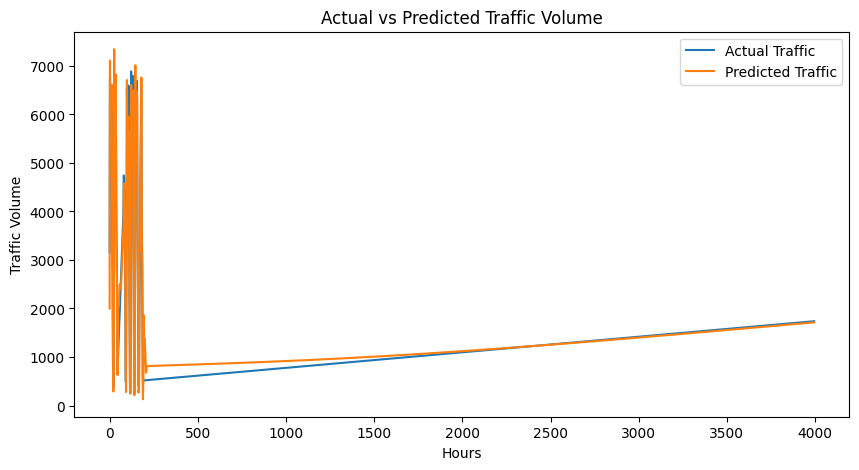

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(actual, label="Actual Traffic")
plt.plot(predicted, label="Predicted Traffic")
plt.xlabel("Hours")
plt.ylabel("Traffic Volume")
plt.title("Actual vs Predicted Traffic Volume")
plt.legend()
plt.show()

In [24]:
# Take the latest 24 hours
last_24_hours = data[-20:]

# Normalize the input
input_data = scaler.transform(
    np.asarray(last_24_hours).reshape(-1, 1)
)

# Reshape for LSTM
input_data = input_data.reshape(1, 20, 1)

# Predict next-hour traffic
prediction = model.predict(input_data, verbose=0)

# Convert to original traffic volume
prediction = scaler.inverse_transform(prediction)

print("Predicted traffic volume for the next hour:",
      round(prediction[0][0]), "vehicles")

Predicted traffic volume for the next hour: 602 vehicles
